# Exploration of data

In [1]:
from utils import *

In [5]:
#import the data and clean it a little
raw_data = pd.read_csv("residential_solar_installations_panel_data_contiguous_US.csv", index_col=0)

features = ['avg GHI (W/m^2)',
            'ACS: number of households (2016)',
            'ACS: housing unit density (/mile^2, 2016)',
            'ACS: median household income (inflation adjusted $ in 2016, 2016)',
            'ACS: % housing units occupied (2016)',
            'ACS: % housing units occupied by renters (2016)',
            'ACS: avg number of years of education (2016)',
            'ACS: median age',
            'ACS: racial diversity (Gini Simpson index)']

columns = features + ['cumulative num of residential PVs by 2016', 'number of buildings']

raw_data = raw_data.dropna(axis=0, how='any', subset=columns) #drop all the rows that have any missing values in the columns we care about
raw_data = raw_data[raw_data['number of buildings']>0] #only keep rows with at least some buildings in them

In [6]:
#group by county
blockgroups_fips = [fips if len(fips)==12 else '0'+fips for fips in raw_data.index.astype(str).values]
county_codes = [fips[:5] for fips in blockgroups_fips]

raw_data['County code'] = county_codes

columns += ['County code']

raw_data = raw_data[columns].groupby('County code').agg({
    'avg GHI (W/m^2)':'mean', 
    'ACS: number of households (2016)':'sum', 
    'ACS: housing unit density (/mile^2, 2016)':'mean',
    'ACS: median household income (inflation adjusted $ in 2016, 2016)':'median', 
    'ACS: % housing units occupied (2016)':'mean', 
    'ACS: % housing units occupied by renters (2016)':'mean',
    'ACS: avg number of years of education (2016)':'mean', 
    'ACS: median age': 'median', 
    'ACS: racial diversity (Gini Simpson index)':'mean',
    'cumulative num of residential PVs by 2016':'sum',
    'number of buildings':'sum'
})

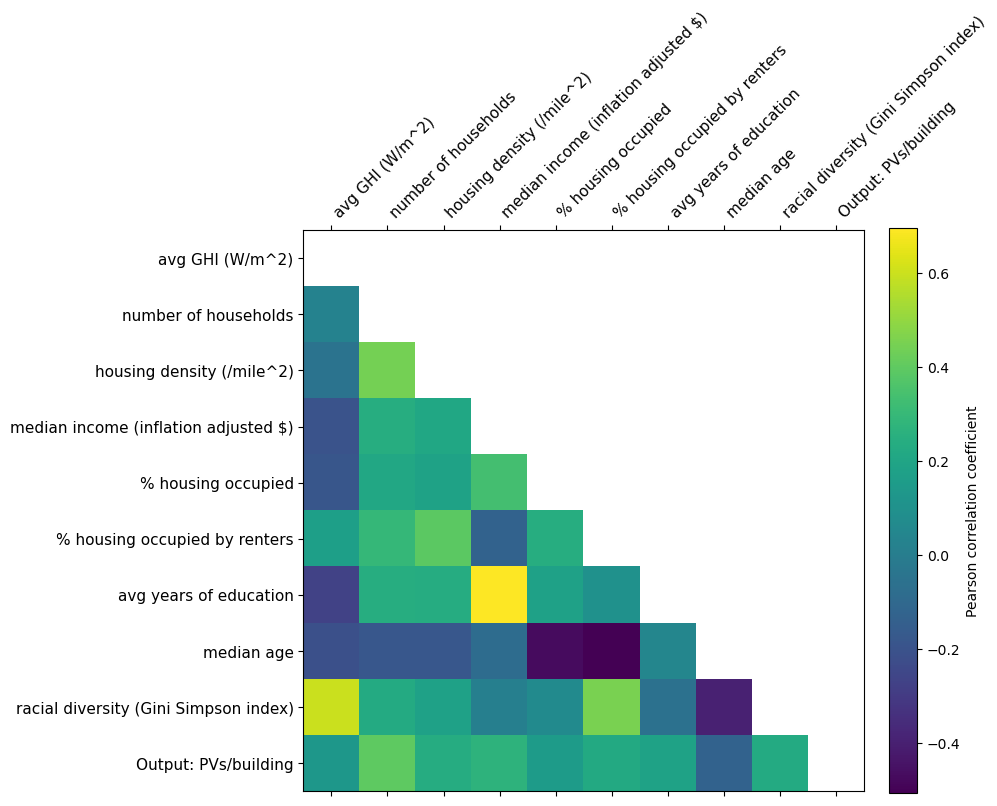

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))

#add output column to get correlation to that
raw_data['Output: PVs/building (2016)'] = raw_data['cumulative num of residential PVs by 2016']/raw_data['number of buildings']
corr = raw_data[features + ['Output: PVs/building (2016)']].corr()

mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
corr[mask] = np.nan

matshow = ax.matshow(corr)

features_simple = ['avg GHI (W/m^2)',
            'number of households',
            'housing density (/mile^2)',
            'median income (inflation adjusted $)',
            '% housing occupied',
            '% housing occupied by renters',
            'avg years of education',
            'median age',
            'racial diversity (Gini Simpson index)']

ax.set_xticks(range(10))
ax.set_xticklabels(features_simple + ['Output: PVs/building'], rotation=45, ha='left', fontsize=11)
ax.set_yticks(range(10))
ax.set_yticklabels(features_simple + ['Output: PVs/building'], fontsize=11)

cbar = fig.colorbar(matshow, fraction=0.046, pad=0.04)
cbar.ax.set_ylabel("Pearson correlation coefficient");

# plt.show()
fig.tight_layout()
# fig.savefig("images/feature_correlation.png", dpi=150)

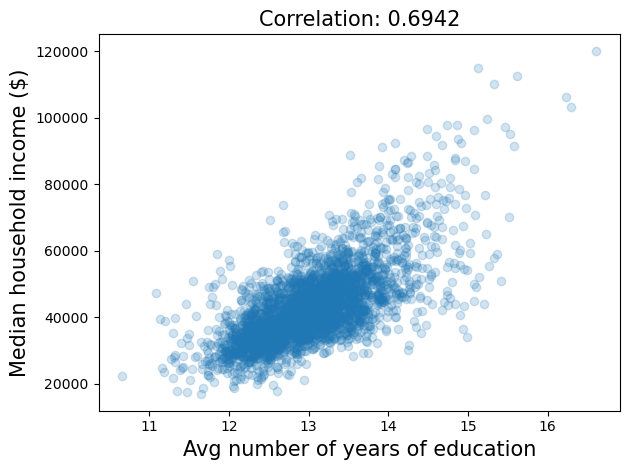

In [14]:
fig, ax = plt.subplots()

x = raw_data['ACS: avg number of years of education (2016)']
y = raw_data['ACS: median household income (inflation adjusted $ in 2016, 2016)']

ax.scatter(x, y, alpha=0.2)

ax.set_xlabel("Avg number of years of education", fontsize=15)
ax.set_ylabel("Median household income ($)", fontsize=15)
ax.tick_params(labelsize=10)

ax.set_title(f"Correlation: {x.corr(y):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/education_income.png", dpi=150)

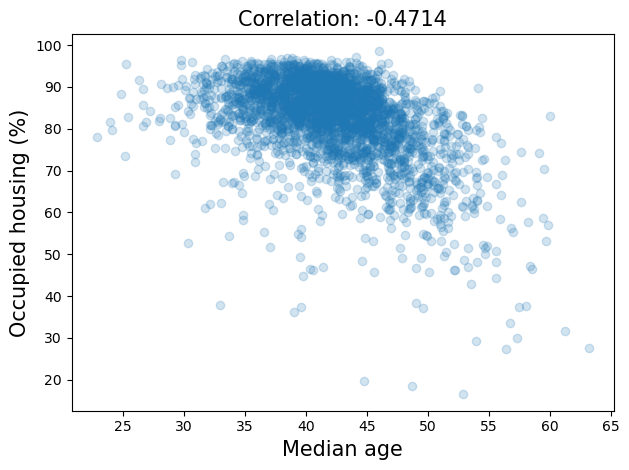

In [17]:
fig, ax = plt.subplots()

x = raw_data['ACS: median age']
y = raw_data['ACS: % housing units occupied (2016)']

ax.scatter(x, y, alpha=0.2)

ax.set_xlabel("Median age", fontsize=15)
ax.set_ylabel("Occupied housing (%)", fontsize=15)
ax.tick_params(labelsize=10)

ax.set_title(f"Correlation: {x.corr(y):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/age_occupied.png", dpi=150)

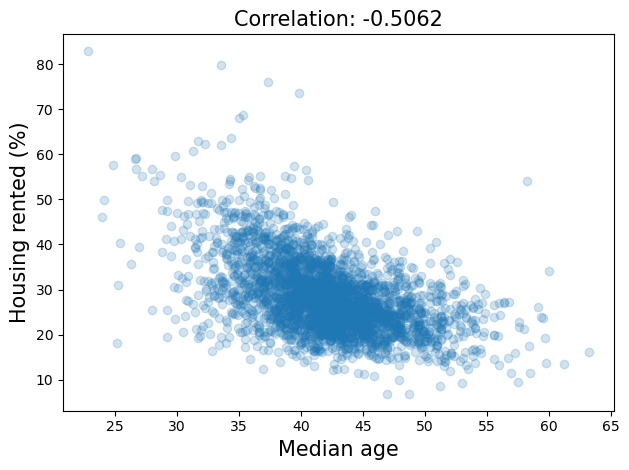

In [16]:
fig, ax = plt.subplots()

x = raw_data['ACS: median age']
y = raw_data['ACS: % housing units occupied by renters (2016)']

ax.scatter(x, y, alpha=0.2)

ax.set_xlabel("Median age", fontsize=15)
ax.set_ylabel("Housing rented (%)", fontsize=15)
ax.tick_params(labelsize=10)

ax.set_title(f"Correlation: {x.corr(y):.4f}", fontsize=15)

fig.tight_layout()
# fig.savefig("images/renters_age.png", dpi=150)